In [1]:
import pandas as pd

df = pd.read_csv("./news_detection.csv")

df.head(3)

,text,label
0,Donald Trump just couldn t wish all Americans ...,False
1,House Intelligence Committee Chairman Devin Nu...,False
2,"On Friday, it was revealed that former Milwauk...",False


In [2]:
df.label.value_counts()

label
False    23481
True     21417
Name: count, dtype: int64

In [6]:
df_True = df[df.label == True].sample(2000, random_state=42)
df_False = df[df.label == False].sample(2000, random_state=42)

df = pd.concat([df_True, df_False], axis=0)

df

,text,label
41618,BRUSSELS (Reuters) - A leading European rights...,True
26758,"(Reuters) - In September 2014, Gilberto Velasq...",True
26357,HAMBURG (Reuters) - U.S. President Donald Trum...,True
28641,NEW YORK (Reuters) - A federal judge rejected ...,True
34324,"ORANGEBURG, S.C. (Reuters) - If Democratic hop...",True
...,...,...
1034,Joe Biden was speaking at the SkyBridge Altern...,False
5505,Speaker Paul Ryan put on a public temper tantr...,False
3189,The former Labor Secretary penned a short mess...,False
3566,It s no secret that team Trump is all in a tiz...,False


In [10]:
import spacy
nlp = spacy.load("en_core_web_sm")

def preprocess(text):
    doc = nlp(text)
    res = ' '.join([token.lemma_ for token in doc if not token.is_stop and not token.is_punct])
    return res.lower()

df["clean_news"] = df.text.apply(preprocess)
df["label_index"] = df.label.map({
    True: 0,
    False: 1
})

In [11]:
df

,text,label,clean_news,label_index
41618,BRUSSELS (Reuters) - A leading European rights...,True,brussels reuters lead european right watchdog ...,0
26758,"(Reuters) - In September 2014, Gilberto Velasq...",True,reuters september 2014 gilberto velasquez 38 y...,0
26357,HAMBURG (Reuters) - U.S. President Donald Trum...,True,hamburg reuters u.s. president donald trump sa...,0
28641,NEW YORK (Reuters) - A federal judge rejected ...,True,new york reuters federal judge reject request ...,0
34324,"ORANGEBURG, S.C. (Reuters) - If Democratic hop...",True,orangeburg s.c. reuters democratic hopeful ber...,0
...,...,...,...,...
1034,Joe Biden was speaking at the SkyBridge Altern...,False,joe biden speak skybridge alternatives salt co...,1
5505,Speaker Paul Ryan put on a public temper tantr...,False,speaker paul ryan public temper tantrum fbi di...,1
3189,The former Labor Secretary penned a short mess...,False,labor secretary pen short message aim donald t...,1
3566,It s no secret that team Trump is all in a tiz...,False,s secret team trump tizzy jill stein s recount...,1


In [14]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(df.clean_news, df.label_index, test_size=0.2, random_state=42, stratify= df.label_index)

Logistic Regression

In [15]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline

clf = Pipeline([
    ("vectorizer", TfidfVectorizer()),
    ("model", LogisticRegression())
])

clf.fit(X_train, y_train)
y_predict = clf.predict(X_test)

In [16]:
from sklearn.metrics import accuracy_score, classification_report

print("Accuracy Score: ",accuracy_score(y_test, y_predict))
print("Classification Report: ",classification_report(y_test, y_predict))

Accuracy Score:  0.9625
Classification Report:                precision    recall  f1-score   support

           0       0.96      0.97      0.96       400
           1       0.97      0.96      0.96       400

    accuracy                           0.96       800
   macro avg       0.96      0.96      0.96       800
weighted avg       0.96      0.96      0.96       800



In [18]:
from sklearn.svm import SVC
clf = Pipeline([
    ("vectorizer", TfidfVectorizer()),
    ("model", SVC())
])

clf.fit(X_train, y_train)
y_predict = clf.predict(X_test)

In [19]:

print("Accuracy Score: ",accuracy_score(y_test, y_predict))
print("Classification Report: ",classification_report(y_test, y_predict))

Accuracy Score:  0.9625
Classification Report:                precision    recall  f1-score   support

           0       0.95      0.98      0.96       400
           1       0.98      0.95      0.96       400

    accuracy                           0.96       800
   macro avg       0.96      0.96      0.96       800
weighted avg       0.96      0.96      0.96       800



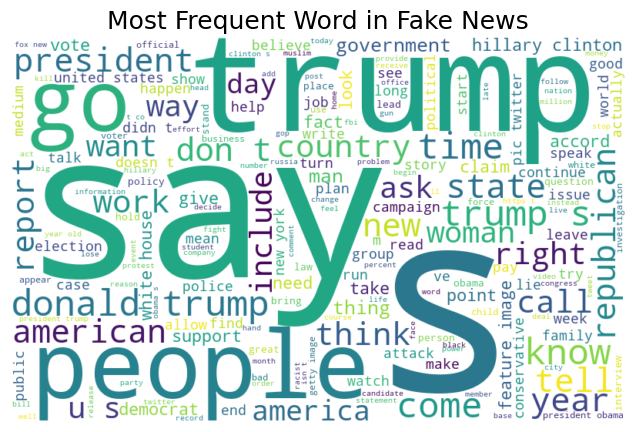

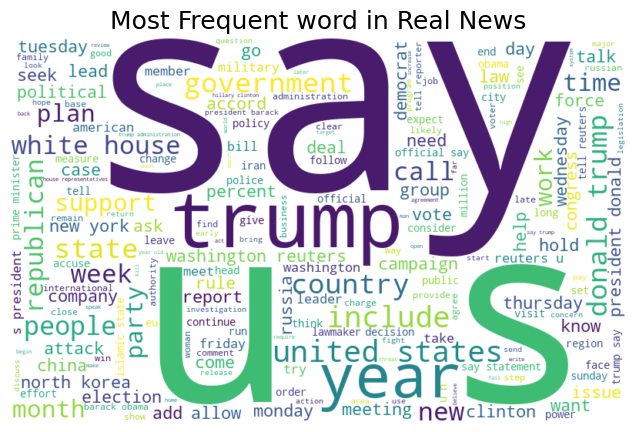

In [23]:
from wordcloud import WordCloud 
import matplotlib.pyplot as plt

def plot_word_cloud(news, title):
    text = " ".join(news)
    wc = WordCloud(width=800, height=500, background_color="white").generate(text)
    plt.figure(figsize=(10, 5))
    plt.imshow(wc, interpolation="bilinear")
    plt.axis("off")
    plt.title(title, fontsize=18)
    plt.show()

plot_word_cloud(df[df["label_index"]==1]["clean_news"], "Most Frequent Word in Fake News")

plot_word_cloud(df[df["label_index"]==0]["clean_news"], "Most Frequent word in Real News")